# Error Analysis

Compare ERM and Group DRO predictions on the same CivilComments-WILDS test examples. The notebook studies corrected errors, newly introduced errors, shared errors, identity-specific false-positive and false-negative rates, and prediction-confidence changes.

In [ ]:
#from google.colab import drive
#drive.mount("/content/drive")

from pathlib import Path
import os

#PROJECT_ROOT = Path("/content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments")
#if not PROJECT_ROOT.exists():
#    raise FileNotFoundError(PROJECT_ROOT)

#os.chdir(PROJECT_ROOT)
#print("Project root:", Path.cwd())


Mounted at /content/drive
Project root: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(); pd.set_option("display.max_columns",None); pd.set_option("display.max_rows",100); pd.set_option("display.max_colwidth",300)
print("Imports successful")


Imports successful


In [5]:
ERM_DIR=Path("results/erm"); DRO_DIR=Path("results/group_dro"); ERROR_DIR=Path("results/error_analysis"); FIGURE_DIR=Path("../figures/results")
ERROR_DIR.mkdir(parents=True,exist_ok=True); FIGURE_DIR.mkdir(parents=True,exist_ok=True)
for p in [ERM_DIR/"test_predictions.csv",DRO_DIR/"test_predictions.csv"]:
    if not p.exists(): raise FileNotFoundError(f"Missing prediction file: {p}")
erm_df=pd.read_csv(ERM_DIR/"test_predictions.csv"); dro_df=pd.read_csv(DRO_DIR/"test_predictions.csv")
print("ERM",erm_df.shape,"Group DRO",dro_df.shape)


ERM (132730, 29) Group DRO (132730, 30)


## Align Identical Test Examples


In [6]:
assert len(erm_df)==len(dro_df)
needed={"true_label","prediction","prob_non_toxic","prob_toxic"}
for name,df in [("ERM",erm_df),("Group DRO",dro_df)]:
    miss=needed-set(df.columns)
    if miss: raise ValueError(f"{name} missing: {sorted(miss)}")

if "uid" in erm_df.columns and "uid" in dro_df.columns:
    assert erm_df.uid.is_unique and dro_df.uid.is_unique
    cols=["uid","true_label","prediction","prob_non_toxic","prob_toxic"]
    comparison_df=erm_df.merge(dro_df[cols],on="uid",how="inner",suffixes=("_erm","_dro"),validate="one_to_one")
    assert len(comparison_df)==len(erm_df)
    assert np.array_equal(comparison_df.true_label_erm,comparison_df.true_label_dro)
    comparison_df["true_label"]=comparison_df.true_label_erm
    comparison_df=comparison_df.drop(columns=["true_label_erm","true_label_dro"])
else:
    assert np.array_equal(erm_df.true_label.values,dro_df.true_label.values)
    comparison_df=erm_df.copy().rename(columns={"prediction":"prediction_erm","prob_non_toxic":"prob_non_toxic_erm","prob_toxic":"prob_toxic_erm"})
    comparison_df["prediction_dro"]=dro_df.prediction.values
    comparison_df["prob_non_toxic_dro"]=dro_df.prob_non_toxic.values
    comparison_df["prob_toxic_dro"]=dro_df.prob_toxic.values

comparison_df=comparison_df.rename(columns={"prediction_erm":"erm_prediction","prediction_dro":"dro_prediction","prob_non_toxic_erm":"erm_prob_non_toxic","prob_non_toxic_dro":"dro_prob_non_toxic","prob_toxic_erm":"erm_prob_toxic","prob_toxic_dro":"dro_prob_toxic"})
required=["true_label","erm_prediction","dro_prediction","erm_prob_toxic","dro_prob_toxic"]
miss=[c for c in required if c not in comparison_df.columns]
if miss: raise ValueError(f"Missing comparison columns: {miss}")
print("Aligned comparison shape:",comparison_df.shape)


Aligned comparison shape: (132730, 32)


## Outcome Categories


In [7]:
comparison_df["erm_correct"]=comparison_df.erm_prediction==comparison_df.true_label
comparison_df["dro_correct"]=comparison_df.dro_prediction==comparison_df.true_label
conditions=[comparison_df.erm_correct&comparison_df.dro_correct,~comparison_df.erm_correct&comparison_df.dro_correct,comparison_df.erm_correct&~comparison_df.dro_correct,~comparison_df.erm_correct&~comparison_df.dro_correct]
categories=["Both correct","Group DRO fixed ERM error","Group DRO introduced error","Both wrong"]
comparison_df["outcome"]=np.select(conditions,categories,default="Unknown")
outcome_summary=comparison_df.outcome.value_counts().reindex(categories).fillna(0).astype(int).rename_axis("outcome").reset_index(name="count")
outcome_summary["percentage"]=outcome_summary["count"]/len(comparison_df)*100
outcome_summary


,outcome,count,percentage
0,Both correct,108436,81.696677
1,Group DRO fixed ERM error,3593,2.706999
2,Group DRO introduced error,14039,10.577111
3,Both wrong,6662,5.019212


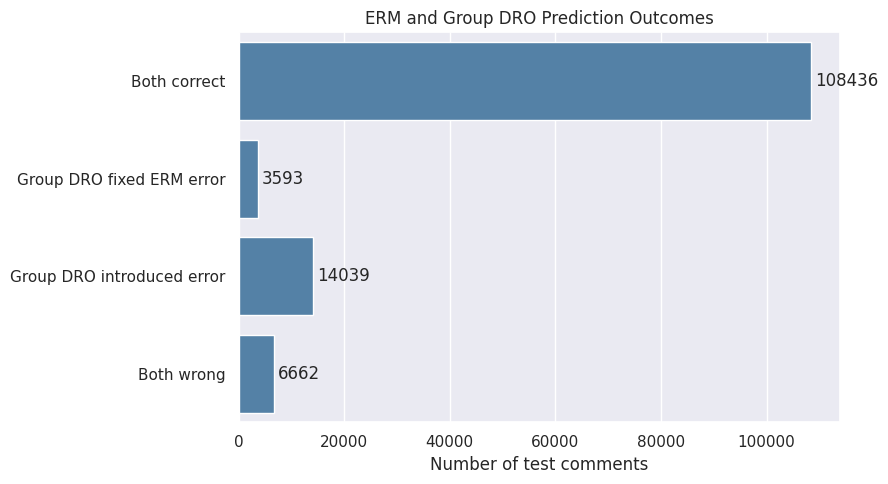

In [8]:
plt.figure(figsize=(9,5)); ax=sns.barplot(data=outcome_summary,y="outcome",x="count",color="steelblue"); ax.bar_label(ax.containers[0],padding=3)
plt.xlabel("Number of test comments"); plt.ylabel(""); plt.title("ERM and Group DRO Prediction Outcomes"); plt.tight_layout()
plt.savefig(FIGURE_DIR/"prediction_outcomes.png",dpi=300,bbox_inches="tight"); plt.show()


## False Positives and False Negatives


,Method,False positives,False negatives
0,ERM,4238,6017
1,Group DRO,17858,2843


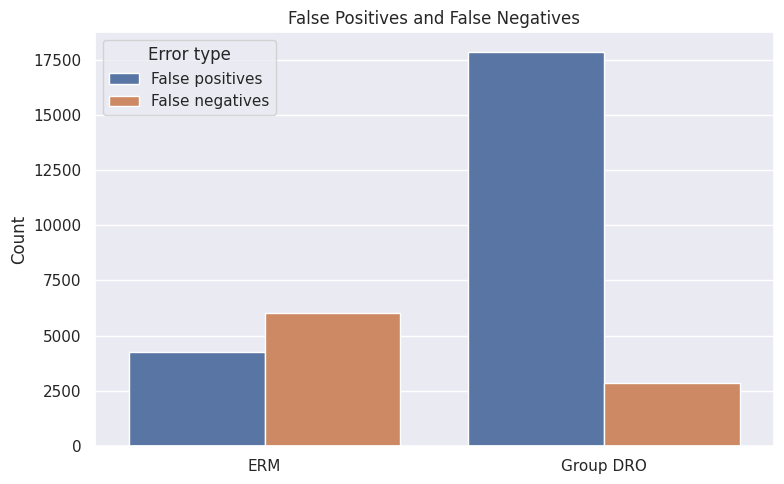

In [9]:
comparison_df["erm_false_positive"]=(comparison_df.true_label==0)&(comparison_df.erm_prediction==1)
comparison_df["erm_false_negative"]=(comparison_df.true_label==1)&(comparison_df.erm_prediction==0)
comparison_df["dro_false_positive"]=(comparison_df.true_label==0)&(comparison_df.dro_prediction==1)
comparison_df["dro_false_negative"]=(comparison_df.true_label==1)&(comparison_df.dro_prediction==0)
error_type_summary=pd.DataFrame({"Method":["ERM","Group DRO"],"False positives":[int(comparison_df.erm_false_positive.sum()),int(comparison_df.dro_false_positive.sum())],"False negatives":[int(comparison_df.erm_false_negative.sum()),int(comparison_df.dro_false_negative.sum())]})
display(error_type_summary)
error_plot=error_type_summary.melt(id_vars="Method",var_name="Error type",value_name="Count")
plt.figure(figsize=(8,5)); sns.barplot(data=error_plot,x="Method",y="Count",hue="Error type"); plt.xlabel(""); plt.title("False Positives and False Negatives"); plt.tight_layout()
plt.savefig(FIGURE_DIR/"false_positive_negative_counts.png",dpi=300,bbox_inches="tight"); plt.show()


## Errors Fixed, Introduced, and Shared


In [10]:
dro_fixes=comparison_df.query("outcome == 'Group DRO fixed ERM error'").copy()
dro_new_errors=comparison_df.query("outcome == 'Group DRO introduced error'").copy()
both_wrong=comparison_df.query("outcome == 'Both wrong'").copy()
fixed_summary=pd.DataFrame({"Error type":["ERM false positive fixed","ERM false negative fixed"],"Count":[int(((dro_fixes.true_label==0)&(dro_fixes.erm_prediction==1)&(dro_fixes.dro_prediction==0)).sum()),int(((dro_fixes.true_label==1)&(dro_fixes.erm_prediction==0)&(dro_fixes.dro_prediction==1)).sum())]})
introduced_summary=pd.DataFrame({"Error type":["New false positive","New false negative"],"Count":[int(((dro_new_errors.true_label==0)&(dro_new_errors.dro_prediction==1)).sum()),int(((dro_new_errors.true_label==1)&(dro_new_errors.dro_prediction==0)).sum())]})
both_wrong_summary=pd.DataFrame({"Error type":["Both false positive","Both false negative"],"Count":[int(((both_wrong.true_label==0)&(both_wrong.erm_prediction==1)&(both_wrong.dro_prediction==1)).sum()),int(((both_wrong.true_label==1)&(both_wrong.erm_prediction==0)&(both_wrong.dro_prediction==0)).sum())]})
print("Fixed"); display(fixed_summary); print("Introduced"); display(introduced_summary); print("Both wrong"); display(both_wrong_summary)


Fixed


,Error type,Count
0,ERM false positive fixed,279
1,ERM false negative fixed,3314


Introduced


,Error type,Count
0,New false positive,13899
1,New false negative,140


Both wrong


,Error type,Count
0,Both false positive,3959
1,Both false negative,2703


## Identity-Specific Error Rates


In [11]:
IDENTITY_COLUMNS=["male","female","LGBTQ","christian","muslim","other_religions","black","white"]
missing=[i for i in IDENTITY_COLUMNS if i not in comparison_df.columns]
if missing: raise ValueError(f"Missing identity columns: {missing}")
rows=[]
for identity in IDENTITY_COLUMNS:
    mask=comparison_df[identity]>=0.5
    non_toxic=comparison_df[mask&(comparison_df.true_label==0)]
    toxic=comparison_df[mask&(comparison_df.true_label==1)]
    rows.append({"identity":identity,"n_non_toxic":len(non_toxic),"n_toxic":len(toxic),"ERM_FPR":np.nan if len(non_toxic)==0 else (non_toxic.erm_prediction==1).mean(),"GroupDRO_FPR":np.nan if len(non_toxic)==0 else (non_toxic.dro_prediction==1).mean(),"ERM_FNR":np.nan if len(toxic)==0 else (toxic.erm_prediction==0).mean(),"GroupDRO_FNR":np.nan if len(toxic)==0 else (toxic.dro_prediction==0).mean()})
identity_errors=pd.DataFrame(rows)
identity_errors["FPR_change"]=identity_errors.GroupDRO_FPR-identity_errors.ERM_FPR
identity_errors["FNR_change"]=identity_errors.GroupDRO_FNR-identity_errors.ERM_FNR
identity_errors.round(4)


,identity,n_non_toxic,n_toxic,ERM_FPR,GroupDRO_FPR,ERM_FNR,GroupDRO_FNR,FPR_change,FNR_change
0,male,12019,2187,0.0544,0.1358,0.4303,0.2602,0.0814,-0.1701
1,female,14083,2252,0.0446,0.1279,0.4338,0.2531,0.0833,-0.1807
2,LGBTQ,3193,1205,0.1046,0.2972,0.4506,0.2266,0.1926,-0.2241
3,christian,12050,1254,0.0308,0.0850,0.5159,0.3062,0.0542,-0.2097
4,muslim,5283,1616,0.0863,0.2328,0.4666,0.2723,0.1465,-0.1943
5,other_religions,2947,517,0.0478,0.1520,0.4990,0.2592,0.1042,-0.2398
6,black,3317,1517,0.1299,0.3485,0.3916,0.1918,0.2186,-0.1997
7,white,5644,2208,0.1238,0.3049,0.4072,0.2206,0.1811,-0.1866


## Identity Error-Rate Figures


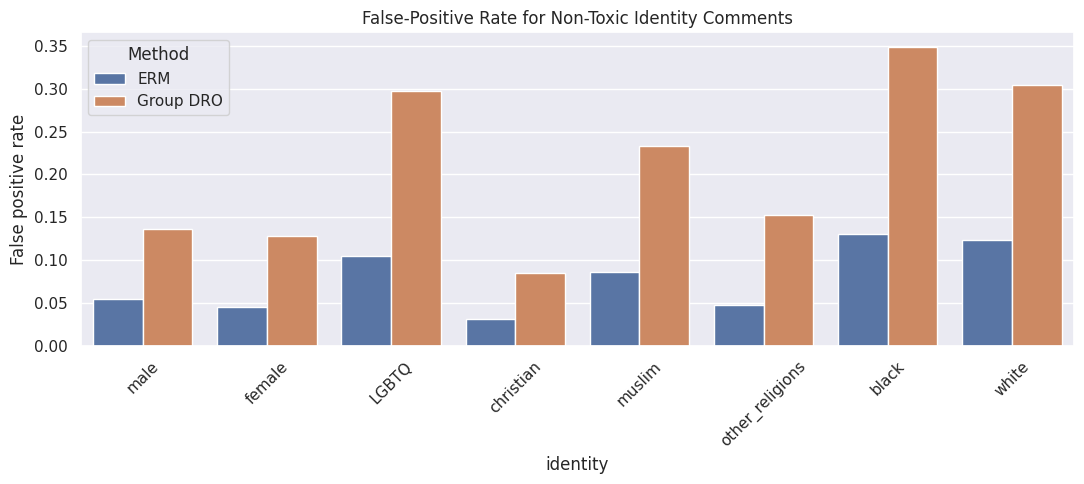

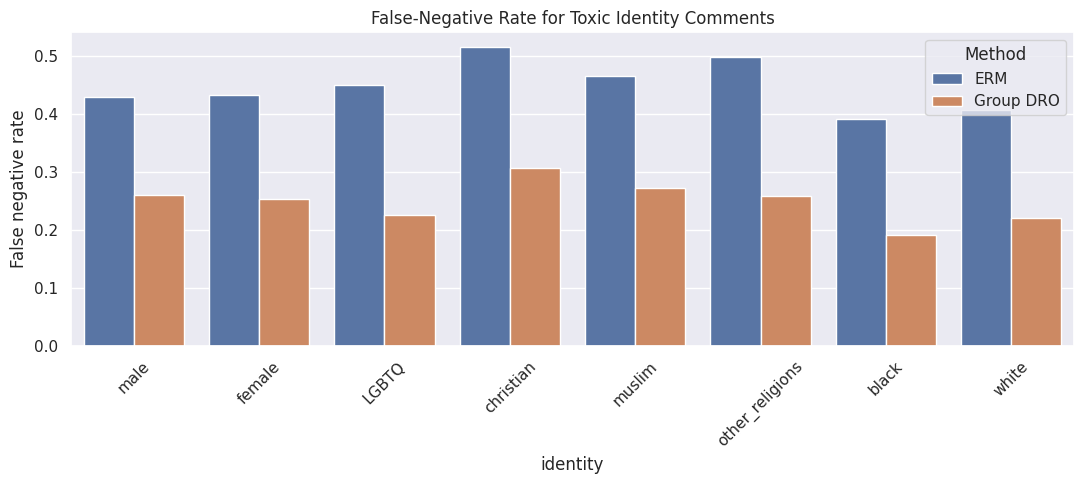

In [12]:
fpr=identity_errors[["identity","ERM_FPR","GroupDRO_FPR"]].melt(id_vars="identity",var_name="Method",value_name="False positive rate")
fpr.Method=fpr.Method.replace({"ERM_FPR":"ERM","GroupDRO_FPR":"Group DRO"})
plt.figure(figsize=(11,5)); sns.barplot(data=fpr,x="identity",y="False positive rate",hue="Method"); plt.xticks(rotation=45); plt.title("False-Positive Rate for Non-Toxic Identity Comments"); plt.tight_layout()
plt.savefig(FIGURE_DIR/"identity_false_positive_rates.png",dpi=300,bbox_inches="tight"); plt.show()

fnr=identity_errors[["identity","ERM_FNR","GroupDRO_FNR"]].melt(id_vars="identity",var_name="Method",value_name="False negative rate")
fnr.Method=fnr.Method.replace({"ERM_FNR":"ERM","GroupDRO_FNR":"Group DRO"})
plt.figure(figsize=(11,5)); sns.barplot(data=fnr,x="identity",y="False negative rate",hue="Method"); plt.xticks(rotation=45); plt.title("False-Negative Rate for Toxic Identity Comments"); plt.tight_layout()
plt.savefig(FIGURE_DIR/"identity_false_negative_rates.png",dpi=300,bbox_inches="tight"); plt.show()


## Prediction-Confidence Changes


,probability_change
count,132730.000000
mean,0.125702
std,0.272578
min,-0.976522
1%,-0.069909
5%,-0.004472
50%,0.007877
95%,0.866154
99%,0.955022
max,0.994775


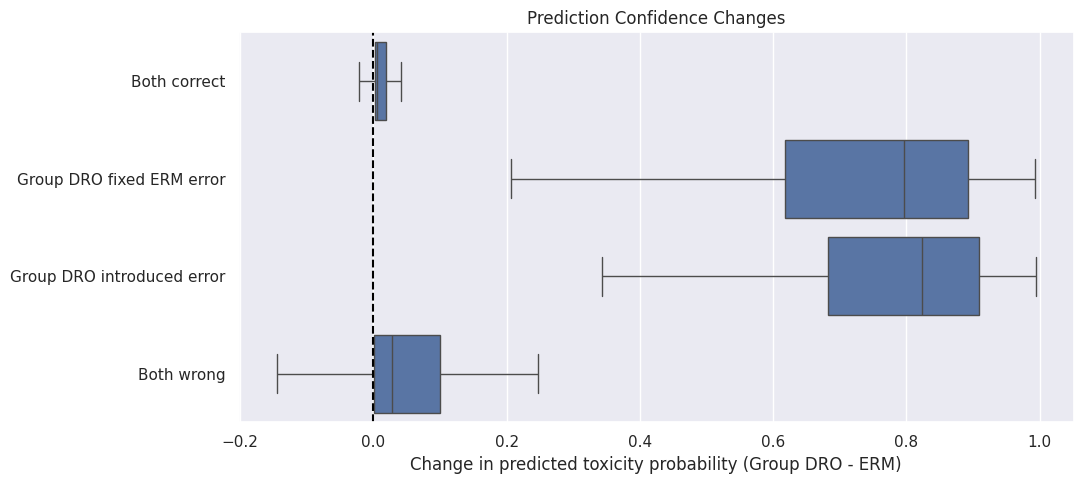

In [13]:
comparison_df["probability_change"]=comparison_df.dro_prob_toxic-comparison_df.erm_prob_toxic
display(comparison_df.probability_change.describe(percentiles=[0.01,0.05,0.5,0.95,0.99]))
plt.figure(figsize=(11,5)); sns.boxplot(data=comparison_df,x="probability_change",y="outcome",order=categories,showfliers=False); plt.axvline(0,color="black",linestyle="--")
plt.xlabel("Change in predicted toxicity probability (Group DRO - ERM)"); plt.ylabel(""); plt.title("Prediction Confidence Changes"); plt.tight_layout()
plt.savefig(FIGURE_DIR/"toxicity_probability_changes.png",dpi=300,bbox_inches="tight"); plt.show()


## Reproducible Qualitative Samples


In [14]:
RANDOM_SEED=42; SAMPLE_SIZE=20
fixed_sample=dro_fixes.sample(n=min(SAMPLE_SIZE,len(dro_fixes)),random_state=RANDOM_SEED)
introduced_sample=dro_new_errors.sample(n=min(SAMPLE_SIZE,len(dro_new_errors)),random_state=RANDOM_SEED)
both_wrong_sample=both_wrong.sample(n=min(SAMPLE_SIZE,len(both_wrong)),random_state=RANDOM_SEED)
review_columns=[c for c in ["uid","comment_text","true_label","erm_prediction","dro_prediction","erm_prob_toxic","dro_prob_toxic","outcome"] if c in comparison_df.columns]
print("Fixed by Group DRO"); display(fixed_sample[review_columns])
print("Introduced by Group DRO"); display(introduced_sample[review_columns])
print("Both wrong"); display(both_wrong_sample[review_columns])


Fixed by Group DRO


,uid,comment_text,true_label,erm_prediction,dro_prediction,erm_prob_toxic,dro_prob_toxic,outcome
103306,346532,Feminist Journo's can't tell the difference and assume anything male and masculine must be toxic. \n\nIt is literally sexism given a hall pass to write whatever. \n\nHelps explain why feminism is dying.,1,0,1,0.084749,0.916866,Group DRO fixed ERM error
8682,29230,"You know, I'm getting tired of getting beat up because I'm a straight, white male. Who can I file a lawsuit aganist....",1,0,1,0.074472,0.940077,Group DRO fixed ERM error
130004,436091,"""Jesus, couldn't teach them 2000+ years ago""\n\nThis is the only truthful statement in your entire comment. That's because \t𝙩𝙝𝙚𝙧𝙚 𝙬𝙚𝙧𝙚 𝙣𝙤 𝙈𝙤𝙨𝙡𝙚𝙢𝙨 𝙪𝙣𝙩𝙞𝙡 𝟔𝟎𝟎 𝙮𝙚𝙖𝙧𝙨 𝙖𝙛𝙩𝙚𝙧 𝙅𝙚𝙨𝙪𝙨 𝙬𝙖𝙡𝙠𝙚𝙙 𝙩𝙝𝙚 𝙚𝙖𝙧𝙩𝙝.\n\nThe rest is nonsense, and even the part that's technically ""truthful"" merely demonstrates an irreme...",1,0,1,0.045823,0.741741,Group DRO fixed ERM error
130202,436704,"""Investigators worked through the night to determine what led a truck driver to plow down people on a riverfront bike path near the World Trade Center, brandishing air guns and yelling “God is great” in Arabic""\n\nGee, it is POSSIBLE that his actions had SOMETHING to do with his membership in th...",1,0,1,0.054370,0.843104,Group DRO fixed ERM error
12494,42222,"Yeah we all know your values. How many murders in your city? Drugs? Gangs? Rahm you are a NIGHTMARE and your inability, gutless unwillingness to act has cost lives. You are the poster boy of a Democratic Mayor with blood on their hands.",1,0,1,0.284503,0.968708,Group DRO fixed ERM error
47743,160273,"So Trump started his political life with a racist lie, and found it resonated with some, so he has stayed with the same message. His strong underlying message is Make America White Again. Unfortunately, racism while not quite as blatant as it once was is still alive and well in America, and Obam...",1,0,1,0.151597,0.915705,Group DRO fixed ERM error
58110,194843,Oh....sounds like someone's white privilege got tweaked.,0,1,0,0.946471,0.177488,Group DRO fixed ERM error
19947,67661,"Well,well.well.....Chris Butler surfaces again. I would love to hear more about his relationship with T and how the guru influences his disciple.... I remember Butler as a damn good baseball player in Kainalu Little League.... Its always important, I believe, to know how religious beliefs INFLUE...",1,0,1,0.009381,0.883092,Group DRO fixed ERM error
125997,422630,".\n\n""The Proud Boys""""\n\n--\n\nHow to describe these guys?\n\nDoofusses? (Doofi?)\n\nEmbittered white males tortured by their loss of privilege and lashing out at their perceived enemies?\n\nRefugees from the 1950s?\n\nObsolete at 25 years of age?\n\nWhatever, they are classic fodder for the fa...",1,0,1,0.430000,0.846769,Group DRO fixed ERM error
112766,378367,"Bravo David Grisham, you got on Alaska's most unwanted list pretty quick. You probably thought this was a red bible thumping state just like yours. This is a don't touch my guns and don't tell us how to live state. This is a big small town, you mess with one Alaskan (even a LGBTQ Alaskan), you m...",1,0,1,0.009931,0.971407,Group DRO fixed ERM error


Introduced by Group DRO


,uid,comment_text,true_label,erm_prediction,dro_prediction,erm_prob_toxic,dro_prob_toxic,outcome
126968,425827,"""someone had jammed a British Fantasy Series Metal Beaded Flogger into the business’s breaker box""\n.\nThat was really specific. Dude knows his whips.",0,0,1,0.004557,0.593864,Group DRO introduced error
74005,247518,"It's only a residence. Unlike some other heads of government our PM does not work from the residence, he has an office in the Centre Block to which he commutes. Likewise, state functions and official entertaining of foreign dignitaries is done at the head of state's residence (Rideau Hall).\n\nI...",0,0,1,0.062455,0.965944,Group DRO introduced error
124930,419026,"4:20 I will ignore the troll. However, I just finished reading an OpEd by Nicholas Kristol titled ""Is Donald Trump a Racist"" from the NYT. As a Trump supporter you should read it. It provides a historical perspective on Mr. Trump's bigotry. Actually, anyone considering supporting Mr. Trump ...",0,0,1,0.073015,0.913336,Group DRO introduced error
76676,256597,It has everything to do with sharia blasphemy laws!\n\nTry criticizing islam if M103 passes and see what happens to you!\n\nWake up!,0,0,1,0.021609,0.835497,Group DRO introduced error
74306,248507,"It's like the politicians on DC, you forgot who works for who. You exist because of my money not the other way around. You turned NFL games into BLM rallies. Big mistake!",0,0,1,0.001231,0.563712,Group DRO introduced error
75847,253748,It looks like FW now gets what it is like to be threatened. It's not fun. I hope that she has learned her lesson. Words matter.,0,0,1,0.001020,0.953105,Group DRO introduced error
67015,224499,McCain and his 2 confederates stopped one attempt. Democrats keep insisting that any effort to change the ACA is a kill attempt so again you can put it squarely on McCain and Democrats.,0,0,1,0.001374,0.504320,Group DRO introduced error
100614,337413,"Go feed your cats, lady.",0,0,1,0.000856,0.992560,Group DRO introduced error
104382,350259,"Evidently, you are ignoring the very first sentences of the story: trauma, mental health loss and physical disability.\n“My sister died..., and my life emotionally started going downhill."" That descent culminated in a nervous breakdown, since which “I can’t really hold things or write correctly ...",0,0,1,0.047713,0.945779,Group DRO introduced error
24574,82891,Try living next to that elephant. You'd soon change your mind.,0,0,1,0.000179,0.741106,Group DRO introduced error


Both wrong


,uid,comment_text,true_label,erm_prediction,dro_prediction,erm_prob_toxic,dro_prob_toxic,outcome
4089,13809,"http://www.theguardian.com/society/2012/jun/05/why-working-class-people-vote-conservative\n the Republican party dupes people into voting against their economic interests by triggering outrage on cultural issues. ""Vote for us and we'll protect the American flag!"" say the Republicans. ""We'll make...",1,0,0,0.009781,0.023857,Both wrong
95323,319156,"How about calling them ""white nationalist terrorists""?\n\n\n\nI mean, Donnie was clutching his pearls that Obama didn't start WWIII by insulting all of Islam at every opportunity and now we have the Christian identity type of home-grown terrorists coming out of the woodwork and NOW he's getting ...",1,0,0,0.074737,0.198931,Both wrong
123314,413641,"A sour ending for Trudeau? What about those of us who believed him, only to discover that he's just another con man in a better cut of suit? Fool me once.......",0,1,1,0.795454,0.991208,Both wrong
49229,165395,"Sharia law has no place in my Canada. Nor does slavery, FGM, murdering gays for being gay or demanding submission to Allah. Honour killings are not the Canadian way, nor is attacking Synagogues. \n\nThere is little hatred for Muslims in Canada, but a growing hatred of radical Islam. Those who...",0,1,1,0.964332,0.980398,Both wrong
36443,122575,"The gay newspapers and blogs are ALL running the story (quelle suprise!) The secretary of the Cardinal (who the Card. had recently recommended for promo to bishop) was holding the ""all male soiree"" in his Vatican apartment, but the reason he was arrested was the huge cache of drugs he was also ...",1,0,0,0.049608,0.140882,Both wrong
127549,427720,"""Woman just want two hours of peace. Which, as many women know, is practically impossible""\nWow, my wife and I just read your article and we are both embarrassed for you. Must be tough for you being a woman with all of these wretched men around. Get some help.",1,0,0,0.006720,0.170052,Both wrong
112838,378595,"Boy, is Trudeau a self-important git or what.",1,0,0,0.000514,0.431701,Both wrong
32734,110237,"The writer is a Marxist and poor black people have taken the place of the ""proletariat"".\nRemember the Marxist newspaper in Russia, Pravda? Pravda means truth in Russian. Typical doublespeack Marxist strategy.\nHe calls his article the ""truth"" for Trudeau. My truth regarding Africans is many Som...",0,1,1,0.912368,0.930130,Both wrong
60957,204348,"Not clear what your point is. Seems to me that if you're dead, who did it doesn't make much difference. You're just as dead.\n\nI'm trying to have a rational conversation here without taking sides. There are cultural issues in play here that aren't being talked about, and the Democratic party...",1,0,0,0.075263,0.192882,Both wrong
56874,190691,"Only to you ad naseum. It should be obvious to any sentient being reading my comment that I picked out liberals since they've been the ones scurrying around this country, frantically laying the racist crap on anyone who disagreed with the POTUS, his administration, the way he does things, what h...",0,1,1,0.923069,0.975088,Both wrong


In [15]:
outcome_summary.to_csv(ERROR_DIR/"prediction_outcome_summary.csv",index=False)
error_type_summary.to_csv(ERROR_DIR/"error_type_summary.csv",index=False)
fixed_summary.to_csv(ERROR_DIR/"fixed_error_summary.csv",index=False)
introduced_summary.to_csv(ERROR_DIR/"introduced_error_summary.csv",index=False)
both_wrong_summary.to_csv(ERROR_DIR/"both_wrong_summary.csv",index=False)
identity_errors.to_csv(ERROR_DIR/"identity_error_rates.csv",index=False)
dro_fixes.to_csv(ERROR_DIR/"dro_fixed_erm_errors.csv",index=False)
dro_new_errors.to_csv(ERROR_DIR/"dro_introduced_errors.csv",index=False)
both_wrong.to_csv(ERROR_DIR/"both_models_wrong.csv",index=False)
print("="*65); print("ERROR ANALYSIS SUMMARY"); print("="*65)
print("Total test examples:",len(comparison_df)); print("ERM errors fixed by Group DRO:",len(dro_fixes)); print("New errors introduced by Group DRO:",len(dro_new_errors)); print("Both wrong:",len(both_wrong))
print("Largest FPR reductions:",identity_errors[["identity","ERM_FPR","GroupDRO_FPR","FPR_change"]].sort_values("FPR_change").head().round(4).to_string(index=False))
print("Largest FNR reductions:",identity_errors[["identity","ERM_FNR","GroupDRO_FNR","FNR_change"]].sort_values("FNR_change").head().round(4).to_string(index=False))

ERROR ANALYSIS SUMMARY
Total test examples: 132730
ERM errors fixed by Group DRO: 3593
New errors introduced by Group DRO: 14039
Both wrong: 6662
Largest FPR reductions:        identity  ERM_FPR  GroupDRO_FPR  FPR_change
      christian   0.0308        0.0850      0.0542
           male   0.0544        0.1358      0.0814
         female   0.0446        0.1279      0.0833
other_religions   0.0478        0.1520      0.1042
         muslim   0.0863        0.2328      0.1465
Largest FNR reductions:        identity  ERM_FNR  GroupDRO_FNR  FNR_change
other_religions   0.4990        0.2592     -0.2398
          LGBTQ   0.4506        0.2266     -0.2241
      christian   0.5159        0.3062     -0.2097
          black   0.3916        0.1918     -0.1997
         muslim   0.4666        0.2723     -0.1943
